# Stage 6: pool identity, Prop. 3 (sanity check only), Enron, GPT-Neo 125M
**Plan:** section 4 row 6, Step I. Post-processing of Stage 2 (10 main seeds, statistic at m = 32); no GPU.

A data owner holds a pool of n_p users, a fraction π of them trained on, plus a disjoint reference set of known non-members
(a random half of the non-members, ≈ 45). **Prop. 3:** KS(pool, non) = π·J(S), one-sided KS. So KS-hat − ε(n_p) − ε(n_ref) is a
lower bound on both J(S) and π. 500 random pools per seed, π and n_p.
**Validity check:** at π = 0 the bound must be ≤ 0 (in ≥ 95% of pools). **Plan expectation:** probably ≤ 0 even at π = 1.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import analysis as A
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
# categorical slots 1-3 (same as Stage 2); ordered groups use one blue ramp, light -> dark
COL = {"T": "#2a78d6", "S_cat": "#eb6834", "Agg": "#1baf7a"}
MRK = {"T": "o", "S_cat": "s", "Agg": "^"}
NAME = {"T": "T̂ (mean)", "S_cat": "S_cat", "Agg": "aggregator (EVAL)"}
RAMP = ["#a9cdf2", "#6aa6e8", "#2a78d6", "#174a8c"]
uv = A.S2.cached_user_values()   # Stage 2 per-user statistics (cached in Stage2/results/_user_values.csv.gz)
print(uv.groupby("run").seed.nunique().to_dict(), "models;", uv.user.nunique(), "users")

{'main': 10, 'null': 1} models; 175 users


In [2]:
pb = pd.concat([A.pool_bounds(uv, st) for st in ["T", "S_cat"]])
sm = A.summarize(pb)
display(sm.round(3))

,stat,m,n_p,pi,seeds,n_ref,ks,pi_times_J,bound,bound_max_seed,p_bound_pos,dkw_terms
0,S_cat,32,15,0.00,10,44.6,0.173,0.000,-0.432,-0.416,0.000,0.604
1,S_cat,32,15,0.25,10,44.6,0.270,0.135,-0.335,-0.308,0.002,0.604
2,S_cat,32,15,0.50,10,44.6,0.384,0.269,-0.220,-0.164,0.023,0.604
3,S_cat,32,15,0.75,10,44.6,0.477,0.404,-0.128,-0.047,0.122,0.604
4,S_cat,32,15,1.00,10,44.6,0.599,0.539,-0.006,0.090,0.481,0.604
5,S_cat,32,25,0.00,10,44.6,0.143,0.000,-0.376,-0.362,0.000,0.518
6,S_cat,32,25,0.25,10,44.6,0.237,0.135,-0.282,-0.257,0.002,0.518
7,S_cat,32,25,0.50,10,44.6,0.342,0.269,-0.176,-0.129,0.026,0.518
8,S_cat,32,25,0.75,10,44.6,0.467,0.404,-0.051,0.025,0.287,0.518
9,S_cat,32,25,1.00,10,44.6,0.578,0.539,0.059,0.155,0.728,0.518


## 1. Lower bound vs π (T̂, m = 32)
Line: mean over pools and seeds; dashed: the Prop. 3 identity π·Ĵ_full minus the same DKW terms.

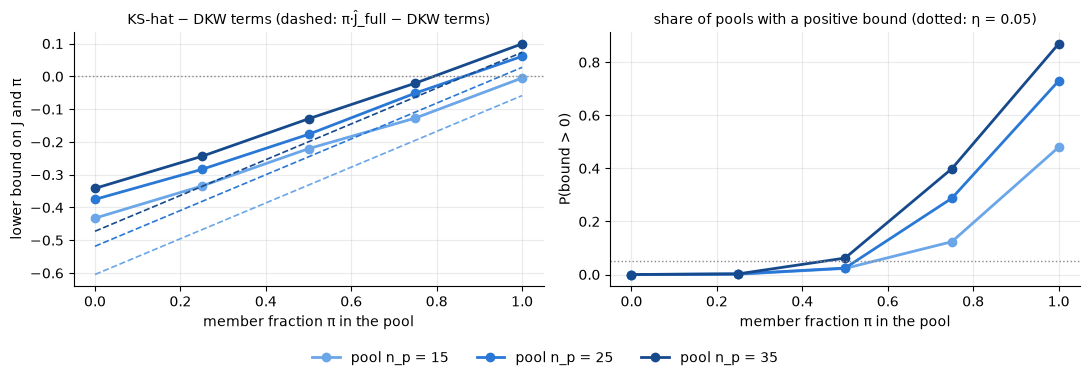

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = sm[sm.stat == "T"]
for i, (n_p, g) in enumerate(x.groupby("n_p")):
    c = RAMP[i + 1]
    axes[0].plot(g.pi, g.bound, marker="o", color=c, lw=2, ms=6, label=f"pool n_p = {n_p}")
    axes[0].plot(g.pi, g.pi_times_J - g.dkw_terms, color=c, lw=1.2, ls="--")
    axes[1].plot(g.pi, g.p_bound_pos, marker="o", color=c, lw=2, ms=6, label=f"pool n_p = {n_p}")
axes[0].axhline(0, color="#888", lw=1, ls=":"); axes[0].set_xlabel("member fraction π in the pool"); axes[0].set_ylabel("lower bound on J and π")
axes[0].set_title("KS-hat − DKW terms (dashed: π·Ĵ_full − DKW terms)", fontsize=10)
axes[1].axhline(.05, color="#888", lw=1, ls=":"); axes[1].set_xlabel("member fraction π in the pool"); axes[1].set_ylabel("P(bound > 0)")
axes[1].set_title("share of pools with a positive bound (dotted: η = 0.05)", fontsize=10)
hs, ls = axes[1].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

## Notes (2026-11-25)
- **Validity at π = 0:** the bound is positive in 1 of 30,000 pools (T̂ and S_cat × 3 pool sizes × 10 seeds × 500), far below η = 0.05; mean bound −0.34 to −0.43. KS-hat at π = 0 is 0.13–0.17, pure small-sample upward bias of the max over thresholds; the DKW terms (0.47–0.60) absorb it.
- **Prop. 3 identity:** KS-hat tracks π·Ĵ_full + the same bias (e.g. n_p = 35: 0.13 / 0.23 / 0.34 / 0.45 / 0.57 vs π·J = 0 / 0.14 / 0.27 / 0.41 / 0.55).
- **Bound at π = 1:** mean +0.10 with n_p = 35 (positive in 87% of pools), +0.06 with n_p = 25 (73%), ≈ 0 with n_p = 15 (48%). At π = 0.75, n_p = 35: positive in 40%. Better than the plan's expectation (≤ 0 even at π = 1), but only for nearly all-member pools of ≥ 25 users.
- **Decision:** sanity check passed; report as the method's limit at Enron's scale (a pool needs ≳ 25 users and π close to 1 to certify anything).